# German Credit Risk Prediction — Projet Machine Learning appliqué à la finance

**Problématique :** Peut-on prédire le risque de crédit d'un demandeur à partir de ses caractéristiques, afin d'aider une banque à prendre une décision tout en tenant compte du coût asymétrique des erreurs?

> Projet pédagogique. Le modèle ne doit pas être utilisé pour prendre de vraies décisions de crédit. Les données historiques sont anciennes, de taille limitée et ne représentent pas nécessairement les demandeurs actuels.

## Objectifs
- Explorer et documenter un dataset public de crédit.
- Préparer des variables numériques et catégorielles.
- Construire une régression logistique avec un pipeline sans fuite de données.
- Comparer à une référence simple.
- Évaluer avec plusieurs métriques et une matrice de coûts.
- Analyser les erreurs et les limites.

**Source :** Statlog German Credit Data, UCI Machine Learning Repository, dataset 144, Hans Hofmann (1994), CC BY 4.0.  
**Reproductibilité :** seed fixe; téléchargement via `ucimlrepo`; preprocessing appris uniquement sur les ensembles d'entraînement.


## 1. Imports et paramètres

In [15]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 30)


In [16]:
!pip install ucimlrepo

## 2. Chargement du dataset

Le dataset comporte 1 000 demandes de crédit et 20 variables descriptives. La cible distingue les dossiers considérés comme `good` (bon risque) et `bad` (mauvais risque). Le dataset UCI original ne contient pas de dates de demandes, donc une validation temporelle n'est pas possible.


In [17]:
# Télécharger le dataset UCI (internet nécessaire la première fois)
dataset = fetch_ucirepo(id=144)
X = dataset.data.features.copy()
y_raw = dataset.data.targets.copy()

# Normaliser la forme de la cible à une Series
if isinstance(y_raw, pd.DataFrame):
    y_raw = y_raw.iloc[:, 0]
else:
    y_raw = pd.Series(y_raw)

print("Dimensions X:", X.shape)
print("Dimensions cible:", y_raw.shape)
display(X.head())
display(dataset.variables)


Dimensions X: (1000, 20)
Dimensions cible: (1000,)


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,Attribute11,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201


,name,role,type,demographic,description,units,missing_values
0,Attribute1,Feature,Categorical,None,Status of existing checking account,None,no
1,Attribute2,Feature,Integer,None,Duration,months,no
2,Attribute3,Feature,Categorical,None,Credit history,None,no
3,Attribute4,Feature,Categorical,None,Purpose,None,no
4,Attribute5,Feature,Integer,None,Credit amount,None,no
5,Attribute6,Feature,Categorical,None,Savings account/bonds,None,no
6,Attribute7,Feature,Categorical,Other,Present employment since,None,no
7,Attribute8,Feature,Integer,None,Installment rate in percentage of disposable i...,None,no
8,Attribute9,Feature,Categorical,Marital Status,Personal status and sex,None,no
9,Attribute10,Feature,Categorical,None,Other debtors / guarantors,None,no


### 2.1 Harmoniser la cible

On code le risque `bad` comme 1 et le risque `good` comme 0. Le code accepte les labels textuels ou numériques (1 = good, 2 = bad dans la source Statlog).


In [18]:
def map_target_to_bad_risk(values):
    s = pd.Series(values).astype(str).str.strip().str.lower()
    unique = set(s.unique())
    # Cas labels textuels
    if unique <= {'good', 'bad'} or {'good', 'bad'}.issubset(unique):
        return s.map({'good': 0, 'bad': 1}).astype(int)
    # Cas encodage Statlog original: 1=good, 2=bad
    numeric = pd.to_numeric(s, errors='coerce')
    if numeric.notna().all() and set(numeric.unique()).issubset({1, 2}):
        return numeric.map({1: 0, 2: 1}).astype(int)
    # Dernier recours : afficher les valeurs pour adapter explicitement
    raise ValueError(f"Encodage cible non reconnu : {sorted(unique)}")

y = map_target_to_bad_risk(y_raw)
y.name = 'bad_risk'
print(y.value_counts().rename({0:'Good risk (0)', 1:'Bad risk (1)'}))
print("Taux de mauvais risque:", round(y.mean()*100, 2), "%")


bad_risk
Good risk (0)    700
Bad risk (1)     300
Name: count, dtype: int64
Taux de mauvais risque: 30.0 %


## 3. Présentation des variables et qualité des données

In [19]:
print("Dimensions :", X.shape)
print("Types :")
display(X.dtypes.value_counts())
print("Valeurs manquantes :")
display(X.isna().sum().sort_values(ascending=False).head(20))
print("Duplications :", X.duplicated().sum())
display(X.describe(include='all').T)


Dimensions : (1000, 20)
Types :


,count
object,13
int64,7


Valeurs manquantes :


,0
Attribute1,0
Attribute2,0
Attribute3,0
Attribute4,0
Attribute5,0
Attribute6,0
Attribute7,0
Attribute8,0
Attribute9,0
Attribute10,0


Duplications : 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Attribute1,1000,4,A14,394,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attribute2,1000.0,NaN,NaN,NaN,20.903,12.058814,4.0,12.0,18.0,24.0,72.0
Attribute3,1000,5,A32,530,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attribute4,1000,10,A43,280,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attribute5,1000.0,NaN,NaN,NaN,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
Attribute6,1000,5,A61,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attribute7,1000,5,A73,339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attribute8,1000.0,NaN,NaN,NaN,2.973,1.118715,1.0,2.0,3.0,4.0,4.0
Attribute9,1000,4,A93,548,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attribute10,1000,3,A101,907,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Exploration visuelle (EDA)

Ces graphiques décrivent la distribution de la cible, des variables numériques, ainsi que les taux de risque selon quelques caractéristiques. Ils ne servent pas à régler le modèle.


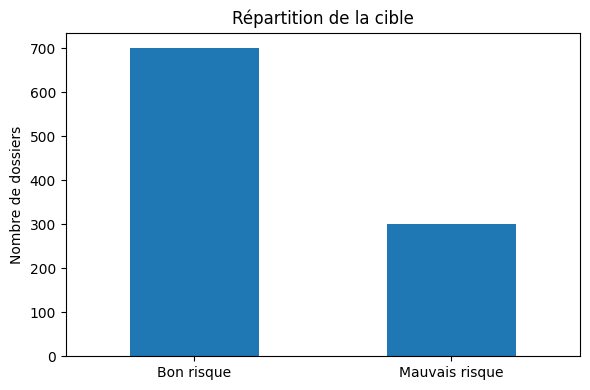

In [20]:
# Répartition des classes
fig, ax = plt.subplots(figsize=(6,4))
counts = y.map({0:'Bon risque', 1:'Mauvais risque'}).value_counts()
counts.plot(kind='bar', ax=ax)
ax.set_title('Répartition de la cible')
ax.set_ylabel('Nombre de dossiers')
ax.set_xlabel('')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


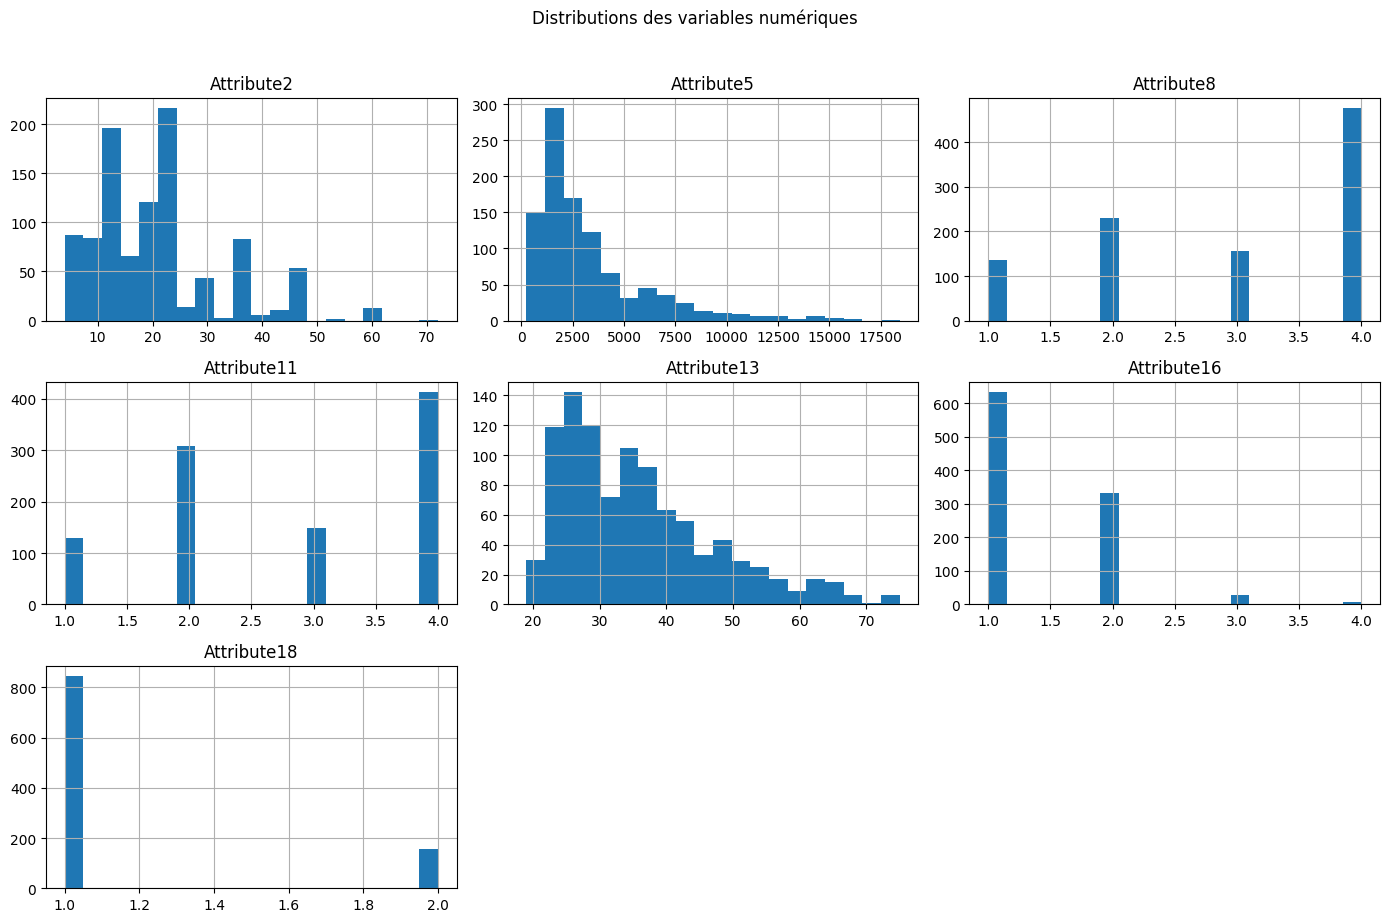

In [21]:
# Variables numériques et distributions
num_cols_eda = X.select_dtypes(include=np.number).columns.tolist()
X[num_cols_eda].hist(figsize=(14,9), bins=20)
plt.suptitle('Distributions des variables numériques', y=1.02)
plt.tight_layout()
plt.show()


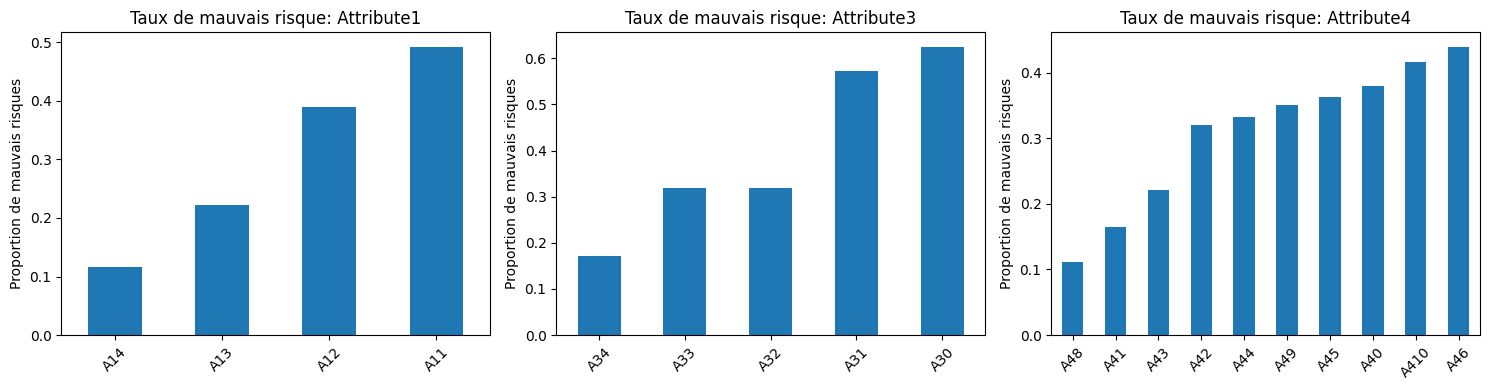

In [22]:
# Quelques variables catégorielles: taux de mauvais risque par catégorie
cat_cols_eda = X.select_dtypes(exclude=np.number).columns.tolist()
candidate_cats = cat_cols_eda[:3]
if candidate_cats:
    fig, axes = plt.subplots(1, len(candidate_cats), figsize=(5*len(candidate_cats),4))
    if len(candidate_cats) == 1:
        axes = [axes]
    for col, ax in zip(candidate_cats, axes):
        rate = pd.DataFrame({'category': X[col].astype(str), 'bad_risk': y}).groupby('category')['bad_risk'].mean().sort_values()
        rate.plot(kind='bar', ax=ax)
        ax.set_title(f'Taux de mauvais risque: {col}')
        ax.set_ylabel('Proportion de mauvais risques')
        ax.set_xlabel('')
        ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()


## 5. Découpage et préparation

Découpage stratifié : 60 % entraînement, 20 % validation, 20 % test. Le jeu de test reste isolé jusqu'à l'évaluation finale. Les imputations, standardisation et encodages sont intégrés dans le Pipeline, donc ils sont ajustés à l'intérieur des folds de validation croisée.


In [23]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, test_size=0.25, stratify=y_train_full,
    random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Validation:", X_valid.shape, "Test:", X_test.shape)


Train: (600, 20) Validation: (200, 20) Test: (200, 20)


In [24]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])


## 6. Référence naïve et coût métier

La référence prédit systématiquement `bon risque`, la classe majoritaire attendue. On compare l'accuracy mais surtout le coût asymétrique inspiré de la matrice UCI : classer un mauvais risque comme bon coûte 5; classer un bon risque comme mauvais coûte 1. Le coût total est :

\[
C = 5\times FN + 1\times FP
\]

où FN correspond aux mauvais risques prédits bons, et FP aux bons risques prédits mauvais.


In [25]:
def business_cost(y_true, y_pred, fn_cost=5, fp_cost=1):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0,1]).ravel()
    return fn_cost*fn + fp_cost*fp, tn, fp, fn, tp

baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_valid)
base_cost, tn, fp, fn, tp = business_cost(y_valid, base_pred)
print("Baseline validation")
print("Accuracy:", accuracy_score(y_valid, base_pred))
print("Cost:", base_cost, "| TN FP FN TP:", tn, fp, fn, tp)


Baseline validation
Accuracy: 0.7
Cost: 300 | TN FP FN TP: 140 0 60 0


## 7. Modèle principal : régression logistique

La régression logistique estime la probabilité qu'une demande soit un mauvais risque. Elle est choisie car elle convient à une classification binaire et reste relativement interprétable. Les coefficients dépendent de la standardisation et de l'encodage des variables.


In [26]:
logit_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(max_iter=3000, class_weight=None, random_state=RANDOM_STATE))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
param_grid = {
    'model__C': [0.01, 0.1, 1, 10],
    'model__class_weight': [None, 'balanced']
}
search = GridSearchCV(
    logit_pipeline, param_grid, scoring='roc_auc',
    cv=cv, n_jobs=-1, return_train_score=True
)
search.fit(X_train, y_train)
best_model = search.best_estimator_
print("Meilleurs paramètres:", search.best_params_)
print("ROC-AUC moyenne CV:", round(search.best_score_, 4))


Meilleurs paramètres: {'model__C': 0.1, 'model__class_weight': 'balanced'}
ROC-AUC moyenne CV: 0.8036


## 8. Choix du seuil sur la validation

Le seuil standard de 0,50 n'est pas forcément optimal lorsque les erreurs ont des coûts différents. Nous choisissons un seuil sur le jeu de validation en minimisant le coût métier, puis nous le figeons avant le test final.


In [27]:
valid_prob = best_model.predict_proba(X_valid)[:, 1]
thresholds = np.arange(0.10, 0.91, 0.02)
threshold_costs = []
for threshold in thresholds:
    pred = (valid_prob >= threshold).astype(int)
    cost, *_ = business_cost(y_valid, pred)
    threshold_costs.append(cost)

best_threshold = float(thresholds[np.argmin(threshold_costs)])
print("Seuil retenu validation:", best_threshold)
print("Coût validation baseline:", base_cost)
print("Coût validation modèle au seuil retenu:", min(threshold_costs))


Seuil retenu validation: 0.3400000000000001
Coût validation baseline: 300
Coût validation modèle au seuil retenu: 101


## 9. Évaluation finale sur test (une seule fois)

Le jeu de test n'a servi ni à choisir les hyperparamètres ni le seuil. Les métriques reportées : accuracy, precision, recall, F1, ROC-AUC et coût métier. Le recall des mauvais risques mesure la part des mauvais risques détectés.


In [28]:
test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

test_cost, tn, fp, fn, tp = business_cost(y_test, test_pred)
metrics = {
    'Accuracy': accuracy_score(y_test, test_pred),
    'Precision (bad risk)': precision_score(y_test, test_pred, zero_division=0),
    'Recall (bad risk)': recall_score(y_test, test_pred, zero_division=0),
    'F1 (bad risk)': f1_score(y_test, test_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, test_prob),
    'Business cost': test_cost
}
test_results = pd.Series(metrics, name='Test results')
display(test_results.to_frame())
print("Confusion matrix (rows=actual, cols=predicted; labels 0 good, 1 bad)")
print(confusion_matrix(y_test, test_pred))
print(classification_report(y_test, test_pred, target_names=['Good risk','Bad risk'], zero_division=0))


,Test results
Accuracy,0.615000
Precision (bad risk),0.430894
Recall (bad risk),0.883333
F1 (bad risk),0.579235
ROC-AUC,0.792619
Business cost,105.000000


Confusion matrix (rows=actual, cols=predicted; labels 0 good, 1 bad)
[[70 70]
 [ 7 53]]
              precision    recall  f1-score   support

   Good risk       0.91      0.50      0.65       140
    Bad risk       0.43      0.88      0.58        60

    accuracy                           0.61       200
   macro avg       0.67      0.69      0.61       200
weighted avg       0.77      0.61      0.63       200



In [29]:
# Test baseline (same test set)
baseline_test_pred = baseline.predict(X_test)
baseline_test_cost, *_ = business_cost(y_test, baseline_test_pred)
baseline_test_acc = accuracy_score(y_test, baseline_test_pred)
print(f"Baseline test accuracy: {baseline_test_acc:.3f}")
print(f"Baseline test cost: {baseline_test_cost}")
print(f"Model test cost: {test_cost}")


Baseline test accuracy: 0.700
Baseline test cost: 300
Model test cost: 105


## 10. Graphiques des résultats

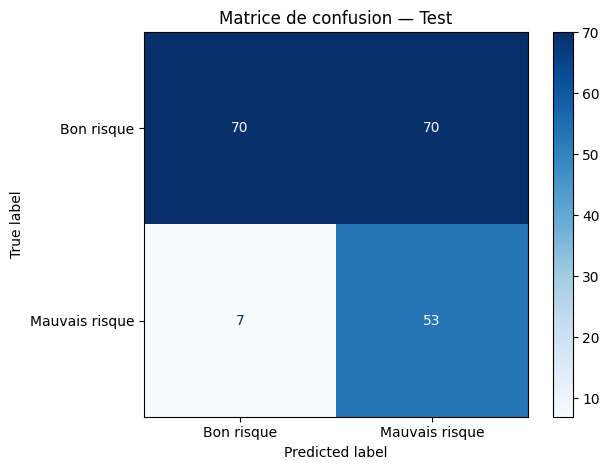

In [30]:
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=['Bon risque','Mauvais risque'],
    cmap='Blues', values_format='d'
)
plt.title('Matrice de confusion — Test')
plt.tight_layout()
plt.show()


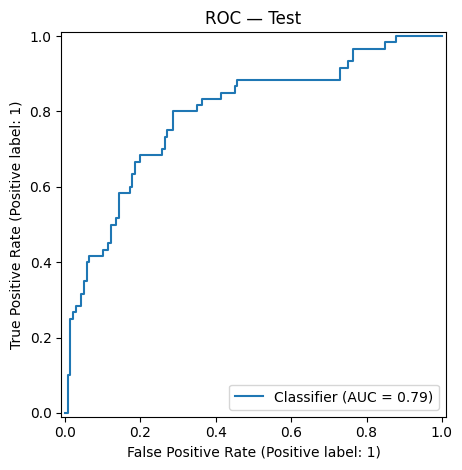

In [31]:
RocCurveDisplay.from_predictions(y_test, test_prob)
plt.title('ROC — Test')
plt.tight_layout()
plt.show()


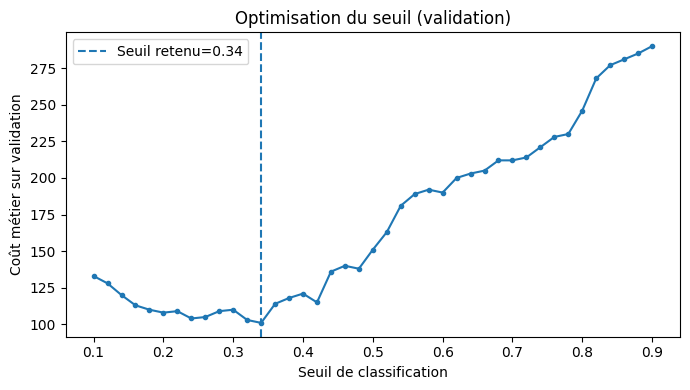

In [32]:
# Coûts selon le seuil sur validation (aucune donnée test ici)
plt.figure(figsize=(7,4))
plt.plot(thresholds, threshold_costs, marker='o', markersize=3)
plt.axvline(best_threshold, linestyle='--', label=f'Seuil retenu={best_threshold:.2f}')
plt.xlabel('Seuil de classification')
plt.ylabel('Coût métier sur validation')
plt.title('Optimisation du seuil (validation)')
plt.legend()
plt.tight_layout()
plt.show()


## 11. Analyse des erreurs

- **FN (faux négatifs)** : un mauvais risque classé bon — erreur la plus coûteuse dans la matrice choisie.
- **FP (faux positifs)** : un bon risque classé mauvais — refus potentiel injustifié, coût moindre dans cette matrice.
- Examiner quelques exemples de test permet de comprendre quels profils sont mal classés, mais sans tirer de conclusions causales.


In [33]:
# Tableau d'erreurs du jeu de test; garder les colonnes originales
error_analysis = X_test.copy()
error_analysis['actual_bad_risk'] = y_test
error_analysis['predicted_bad_risk'] = test_pred
error_analysis['probability_bad_risk'] = test_prob
error_analysis['error_type'] = np.select(
    [
        (y_test.to_numpy()==1) & (test_pred==0),
        (y_test.to_numpy()==0) & (test_pred==1)
    ],
    ['FN: bad predicted good', 'FP: good predicted bad'],
    default='Correct'
)
display(error_analysis[error_analysis['error_type']!='Correct'].head(10))
print(error_analysis['error_type'].value_counts())


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,Attribute11,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20,actual_bad_risk,predicted_bad_risk,probability_bad_risk,error_type
30,A12,18,A32,A49,1913,A64,A72,3,A94,A101,3,A121,36,A141,A152,1,A173,1,A192,A201,0,1,0.574055,FP: good predicted bad
216,A11,18,A30,A49,3104,A61,A74,3,A93,A101,1,A122,31,A141,A152,1,A173,1,A192,A201,0,1,0.651073,FP: good predicted bad
346,A12,13,A34,A43,882,A61,A72,4,A93,A103,4,A121,23,A143,A152,2,A173,1,A191,A201,0,1,0.347147,FP: good predicted bad
112,A12,18,A32,A40,6260,A61,A74,3,A93,A101,3,A121,28,A143,A151,1,A172,1,A191,A201,0,1,0.688771,FP: good predicted bad
875,A12,11,A34,A40,1322,A64,A73,4,A92,A101,4,A123,40,A143,A152,2,A173,1,A191,A201,0,1,0.359471,FP: good predicted bad
877,A14,36,A32,A43,3595,A61,A75,4,A93,A101,2,A123,28,A143,A152,1,A173,1,A191,A201,0,1,0.419246,FP: good predicted bad
412,A14,12,A34,A49,2292,A61,A71,4,A93,A101,2,A123,42,A142,A152,2,A174,1,A192,A201,1,0,0.217226,FN: bad predicted good
801,A12,18,A34,A43,1795,A61,A75,3,A92,A103,4,A121,48,A141,A151,2,A172,1,A192,A201,0,1,0.563656,FP: good predicted bad
779,A12,18,A32,A45,3872,A61,A71,2,A92,A101,4,A123,67,A143,A152,1,A173,1,A192,A201,0,1,0.491297,FP: good predicted bad
562,A13,6,A33,A43,683,A61,A72,2,A92,A101,1,A122,29,A141,A152,1,A173,1,A191,A201,0,1,0.485828,FP: good predicted bad


error_type
Correct                   123
FP: good predicted bad     70
FN: bad predicted good      7
Name: count, dtype: int64


## 12. Interprétation des coefficients

On affiche les coefficients les plus positifs et négatifs après encodage. Les coefficients indiquent une association dans ce modèle, pas une causalité. Ils sont à interpréter avec prudence, notamment pour les catégories.


In [34]:
feature_names = best_model.named_steps['prep'].get_feature_names_out()
coefs = best_model.named_steps['model'].coef_[0]
coef_table = pd.DataFrame({'feature': feature_names, 'coefficient': coefs})
display(coef_table.sort_values('coefficient', ascending=False).head(12))
display(coef_table.sort_values('coefficient').head(12))


,feature,coefficient
7,cat__Attribute1_A11,0.600917
47,cat__Attribute14_A141,0.448248
26,cat__Attribute6_A61,0.388403
2,num__Attribute8,0.364523
23,cat__Attribute4_A46,0.349619
0,num__Attribute2,0.307278
1,num__Attribute5,0.305705
36,cat__Attribute9_A91,0.295314
32,cat__Attribute7_A72,0.259310
11,cat__Attribute3_A30,0.253629


,feature,coefficient
10,cat__Attribute1_A14,-0.743528
15,cat__Attribute3_A34,-0.640981
17,cat__Attribute4_A41,-0.457623
38,cat__Attribute9_A93,-0.438830
49,cat__Attribute14_A143,-0.361288
29,cat__Attribute6_A64,-0.258053
34,cat__Attribute7_A74,-0.248054
30,cat__Attribute6_A65,-0.245546
20,cat__Attribute4_A43,-0.210176
58,cat__Attribute19_A192,-0.203311


## 13. Discussion critique et limites

1. **Données anciennes :** dataset de 1994, comportements et marché du crédit différents aujourd'hui.
2. **Petit échantillon :** 1 000 dossiers, résultats sensibles au découpage.
3. **Absence de temporalité :** impossible d'évaluer la dérive dans le temps ou de faire un split temporel.
4. **Biais de sélection :** la population observée ne reflète pas nécessairement tous les demandeurs; les décisions passées d'acceptation peuvent avoir influencé les données.
5. **Équité et variables sensibles :** certaines variables personnelles peuvent soulever des enjeux réglementaires et éthiques; ce notebook ne réalise pas d'audit complet de fairness.
6. **Coûts simplifiés :** la matrice 5/1 est un choix pédagogique fourni avec le dataset, elle ne représente pas le coût réel de la banque.
7. **Pas de causalité :** les associations du modèle ne prouvent pas qu'une variable cause le défaut.
8. **Déploiement :** ce modèle ne doit pas être déployé tel quel pour décider de vrais crédits.

## 14. Conclusion (à finaliser après exécution)

Après avoir exécuté le notebook, compléter la conclusion avec les valeurs calculées :
- Le modèle améliore-t-il la référence sur le coût métier?
- Quel seuil a été choisi sur validation?
- Quels types d'erreurs restent les plus fréquents?
- La performance semble-t-elle suffisamment stable et utile?
- Que faudrait-il collecter pour une étude plus réaliste (données récentes, dates, suivi des remboursements, audit de biais)?

**Ne pas inventer de résultats.** Les cellules calculent les résultats lorsque le notebook est exécuté.


## 15. Sources et bibliographie

- Hofmann, H. (1994). *Statlog (German Credit Data)*. UCI Machine Learning Repository, dataset 144. DOI: https://doi.org/10.24432/C5NC77
- Documentation officielle UCI : https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data
- Scikit-learn documentation : Pipeline, ColumnTransformer, LogisticRegression, GridSearchCV, metrics.
- Aide UCI : package `ucimlrepo` et API du repository.


## 16. Annexes — reproductibilité

Versions, seed et paramètres sont conservés ci-dessous. Pour reproduire :
1. installer les dépendances;
2. exécuter toutes les cellules de haut en bas;
3. le dataset est téléchargé à partir de l'UCI;
4. le notebook affiche les résultats calculés pour ce run.


In [35]:
import sklearn
print("scikit-learn version:", sklearn.__version__)
print("pandas version:", pd.__version__)
print("numpy version:", np.__version__)
print("Random seed:", RANDOM_STATE)


scikit-learn version: 1.6.1
pandas version: 2.2.3
numpy version: 2.4.6
Random seed: 42
